Melbourne Metro Train Service Explorer

Goal: analyse scheduled metropolitan train services in Melbourne using official Victorian GTFS data.

Questions:
1. Which lines and stations have the most scheduled services?
2. How do weekday and weekend schedules differ?
3. What accessibility information is available in the timetable data?

Note: this project analyses scheduled services, not actual patronage or punctuality.

In [0]:
# Location of the original GTFS files in your Databricks Volume
volume_path = "/Volumes/workspace/default/melbourne_pt_files"

# Read one source file into a Spark DataFrame
routes_df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(f"{volume_path}/routes.txt")
)

# Show the first rows
display(routes_df)

route_id,agency_id,route_short_name,route_long_name,route_type,route_color,route_text_color
aus:vic:vic-02-ALM:,null,Alamein,null,400,152C6B,FFFFFF
aus:vic:vic-02-ALM-R:,null,Replacement Bus,Alamein Line,400,FE5000,FFFFFF
aus:vic:vic-02-BEG:,null,Belgrave,null,400,152C6B,FFFFFF
aus:vic:vic-02-BEG-R:,null,Replacement Bus,Belgrave Line,400,FE5000,FFFFFF
aus:vic:vic-02-CBE:,null,Cranbourne,null,400,34ACE1,000000
aus:vic:vic-02-CBE-R:,null,Replacement Bus,Cranbourne Line,400,FE5000,FFFFFF
aus:vic:vic-02-CCL:,null,City Circle,null,400,0072CE,FFFFFF
aus:vic:vic-02-CCL-R:,null,Replacement Bus,null,400,0072CE,FFFFFF
aus:vic:vic-02-CGB:,null,Craigieburn,null,400,FFBE00,000000
aus:vic:vic-02-CGB-R:,null,Replacement Bus,Craigieburn Line,400,FE5000,FFFFFF


In [0]:
# File names in the Volume and matching table-name endings
files = {
    "routes": "routes.txt",
    "stops": "stops.txt",
    "trips": "trips.txt",
    "stop_times": "stop_times.txt",
    "calendar": "calendar.txt",
    "calendar_dates": "calendar_dates.txt"
}

# Read each file and save it as a Delta table
for name, file_name in files.items():
    df = (
        spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .csv(f"{volume_path}/{file_name}")
    )

    table_name = f"workspace.default.pt_raw_{name}"

    (
        df.write
        .format("delta")
        .mode("overwrite")
        .saveAsTable(table_name)
    )

    print(f"Created: {table_name}")

Created: workspace.default.pt_raw_routes
Created: workspace.default.pt_raw_stops
Created: workspace.default.pt_raw_trips
Created: workspace.default.pt_raw_stop_times
Created: workspace.default.pt_raw_calendar
Created: workspace.default.pt_raw_calendar_dates


In [0]:
display(spark.table("workspace.default.pt_raw_stops").limit(10))

stop_id,stop_name,stop_lat,stop_lon,stop_url,location_type,parent_station,wheelchair_boarding,level_id,platform_code
10117,Jordanville Station,-37.87360157,145.11197651,https://transport.vic.gov.au/stop/1105/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:JOR,1,Level 1,1
10920,Flagstaff Station,-37.81205297,144.95562907,https://transport.vic.gov.au/stop/1068/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:FGS,1,Level -3,1
10921,Flagstaff Station,-37.81192588,144.95557578,https://transport.vic.gov.au/stop/1068/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:FGS,1,Level -3,2
10922,Melbourne Central Station,-37.80997342,144.96251307,https://transport.vic.gov.au/stop/1120/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:MCE,1,Level -2,1
10923,Melbourne Central Station,-37.80986514,144.96250469,https://transport.vic.gov.au/stop/1120/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:MCE,1,Level -2,2
10924,Parliament Station,-37.81105406,144.97291092,https://transport.vic.gov.au/stop/1155/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:PAR,1,Level -2,1
11119,Belgrave Station,-37.90914619,145.35522205,https://transport.vic.gov.au/stop/1018/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:BEG,1,Level 0,1
11120,Belgrave Station,-37.90908138,145.35509837,https://transport.vic.gov.au/stop/1018/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:BEG,1,Level 0,2
11121,Tecoma Station,-37.90799864,145.3428039,https://transport.vic.gov.au/stop/1191/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:TCM,1,Level 0,1
11122,Upwey Station,-37.90355406,145.33121134,https://transport.vic.gov.au/stop/1200/?utm_source=open_data_click_stop&utm_medium=open_data_stop_click&utm_campaign=open_data_click,null,vic:rail:UPW,1,Level 0,1


In [0]:
# Count records in each raw table
raw_tables = [
    "pt_raw_routes",
    "pt_raw_stops",
    "pt_raw_trips",
    "pt_raw_stop_times",
    "pt_raw_calendar",
    "pt_raw_calendar_dates"
]

for table in raw_tables:
    row_count = spark.table(f"workspace.default.{table}").count()
    print(f"{table}: {row_count:,} rows")

pt_raw_routes: 36 rows
pt_raw_stops: 2,859 rows
pt_raw_trips: 40,556 rows
pt_raw_stop_times: 688,380 rows
pt_raw_calendar: 26 rows
pt_raw_calendar_dates: 40 rows


In [0]:
display(
    spark.table("workspace.default.pt_raw_routes")
    .select(
        "route_id",
        "route_short_name",
        "route_long_name",
        "route_type"
    )
)

route_id,route_short_name,route_long_name,route_type
aus:vic:vic-02-ALM:,Alamein,null,400
aus:vic:vic-02-ALM-R:,Replacement Bus,Alamein Line,400
aus:vic:vic-02-BEG:,Belgrave,null,400
aus:vic:vic-02-BEG-R:,Replacement Bus,Belgrave Line,400
aus:vic:vic-02-CBE:,Cranbourne,null,400
aus:vic:vic-02-CBE-R:,Replacement Bus,Cranbourne Line,400
aus:vic:vic-02-CCL:,City Circle,null,400
aus:vic:vic-02-CCL-R:,Replacement Bus,null,400
aus:vic:vic-02-CGB:,Craigieburn,null,400
aus:vic:vic-02-CGB-R:,Replacement Bus,Craigieburn Line,400


In [0]:
from pyspark.sql import functions as F

# Read the raw routes table and create a cleaned route dimension
silver_routes_df = (
    spark.table("workspace.default.pt_raw_routes")
    .withColumn(
        "is_replacement_bus",
        F.col("route_short_name") == "Replacement Bus"
    )
    .withColumn(
        "line_name",
        F.coalesce(F.col("route_long_name"), F.col("route_short_name"))
    )
    .withColumn(
        "service_category",
        F.when(F.col("route_short_name") == "Replacement Bus", "Replacement bus")
         .otherwise("Train line")
    )
    .select(
        "route_id",
        "route_short_name",
        "route_long_name",
        "line_name",
        "route_type",
        "is_replacement_bus",
        "service_category"
    )
)

# Save the cleaned table
(
    silver_routes_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_routes")
)

display(
    spark.table("workspace.default.pt_silver_routes")
    .groupBy("service_category")
    .count()
)

service_category,count
Train line,18
Replacement bus,18


In [0]:
from pyspark.sql import functions as F

stops_df = spark.table("workspace.default.pt_raw_stops")

# Check what kinds of locations exist in the dataset
display(
    stops_df
    .groupBy(F.coalesce(F.col("location_type").cast("string"), F.lit("blank")).alias("location_type"))
    .count()
    .orderBy("location_type")
)

location_type,count
1,226
2,746
3,1112
blank,775


In [0]:
# Check accessibility values
display(
    stops_df
    .groupBy(F.coalesce(F.col("wheelchair_boarding").cast("string"), F.lit("blank")).alias("wheelchair_boarding"))
    .count()
    .orderBy("wheelchair_boarding")
)

wheelchair_boarding,count
0,1
1,1733
2,10
blank,1115


In [0]:
from pyspark.sql import functions as F

# Standardise GTFS location and accessibility fields
silver_stops_df = (
    spark.table("workspace.default.pt_raw_stops")
    .withColumn(
        "location_type_normalised",
        F.coalesce(F.col("location_type").cast("int"), F.lit(0))
    )
    .withColumn(
        "location_category",
        F.when(F.col("location_type_normalised") == 0, "Platform or stop")
         .when(F.col("location_type_normalised") == 1, "Station")
         .when(F.col("location_type_normalised") == 2, "Entrance or exit")
         .when(F.col("location_type_normalised") == 3, "Internal station node")
         .otherwise("Other")
    )
    .withColumn(
        "wheelchair_status",
        F.when(F.col("wheelchair_boarding") == 1, "Accessible")
         .when(F.col("wheelchair_boarding") == 2, "Not accessible")
         .otherwise("Unknown")
    )
    .select(
        "stop_id",
        "stop_name",
        "stop_lat",
        "stop_lon",
        "parent_station",
        "platform_code",
        "level_id",
        "location_type_normalised",
        "location_category",
        "wheelchair_boarding",
        "wheelchair_status"
    )
)

# Save the complete cleaned location table
(
    silver_stops_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_stops")
)

# Keep only timetable boarding points for service analysis
platforms_df = silver_stops_df.filter(
    F.col("location_type_normalised") == 0
)

(
    platforms_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_platforms")
)

# Keep only station-level records for accessibility analysis
stations_df = silver_stops_df.filter(
    F.col("location_type_normalised") == 1
)

(
    stations_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_stations")
)

In [0]:
display(
    spark.sql("""
        SELECT 'Platform or stop' AS table_type,
               COUNT(*) AS records
        FROM workspace.default.pt_silver_platforms

        UNION ALL

        SELECT 'Station',
               COUNT(*)
        FROM workspace.default.pt_silver_stations
    """)
)

table_type,records
Platform or stop,775
Station,226


In [0]:
# Keep only scheduled trips that belong to actual train lines
train_routes_df = (
    spark.table("workspace.default.pt_silver_routes")
    .filter(F.col("is_replacement_bus") == False)
    .select("route_id", "line_name")
)

silver_trips_df = (
    spark.table("workspace.default.pt_raw_trips")
    .join(train_routes_df, on="route_id", how="inner")
    .filter(F.col("trip_id").isNotNull())
    .select(
        "trip_id",
        "route_id",
        "line_name",
        "service_id",
        "trip_headsign",
        "direction_id",
        "block_id",
        "shape_id",
        "wheelchair_accessible",
        "bikes_allowed"
    )
)

(
    silver_trips_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_trips")
)

In [0]:
display(
    spark.table("workspace.default.pt_silver_trips")
    .groupBy("line_name")
    .agg(F.countDistinct("trip_id").alias("scheduled_trips_in_data"))
    .orderBy(F.desc("scheduled_trips_in_data"))
)

line_name,scheduled_trips_in_data
Sunbury,4623
Frankston,3552
Werribee,2864
Pakenham,2601
Sandringham,2593
Lilydale,2470
Craigieburn,2450
Mernda,2228
Upfield,2223
Cranbourne,2188


In [0]:
# Clean regular service-calendar records
silver_calendar_df = (
    spark.table("workspace.default.pt_raw_calendar")
    .withColumn(
        "service_start_date",
        F.to_date(F.col("start_date").cast("string"), "yyyyMMdd")
    )
    .withColumn(
        "service_end_date",
        F.to_date(F.col("end_date").cast("string"), "yyyyMMdd")
    )
    .select(
        "service_id",
        "monday",
        "tuesday",
        "wednesday",
        "thursday",
        "friday",
        "saturday",
        "sunday",
        "service_start_date",
        "service_end_date"
    )
)

(
    silver_calendar_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_calendar")
)

# Clean one-off service additions and removals
silver_calendar_dates_df = (
    spark.table("workspace.default.pt_raw_calendar_dates")
    .withColumn(
        "exception_date",
        F.to_date(F.col("date").cast("string"), "yyyyMMdd")
    )
    .withColumn(
        "exception_type_description",
        F.when(F.col("exception_type") == 1, "Service added")
         .when(F.col("exception_type") == 2, "Service removed")
         .otherwise("Unknown")
    )
    .select(
        "service_id",
        "exception_date",
        "exception_type",
        "exception_type_description"
    )
)

(
    silver_calendar_dates_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_silver_calendar_dates")
)

In [0]:
display(
    spark.table("workspace.default.pt_silver_calendar")
    .agg(
        F.min("service_start_date").alias("first_service_date"),
        F.max("service_end_date").alias("last_service_date"),
        F.countDistinct("service_id").alias("regular_service_patterns")
    )
)

first_service_date,last_service_date,regular_service_patterns
2026-10-08,2026-12-31,26


In [0]:
display(
    spark.table("workspace.default.pt_silver_calendar_dates")
    .groupBy("exception_type_description")
    .count()
)

exception_type_description,count
Service removed,40


In [0]:
# Our first analysis date: Tuesday, 20 October 2026
analysis_date = F.to_date(F.lit("2026-10-20"))

# Find regular services scheduled to run on that Tuesday
active_tuesday_services_df = (
    spark.table("workspace.default.pt_silver_calendar")
    .filter(
        (F.col("service_start_date") <= analysis_date) &
        (F.col("service_end_date") >= analysis_date) &
        (F.col("tuesday") == 1)
    )
    .select("service_id")
)

# Remove services explicitly cancelled for the selected date
removed_services_df = (
    spark.table("workspace.default.pt_silver_calendar_dates")
    .filter(
        (F.col("exception_date") == analysis_date) &
        (F.col("exception_type") == 2)
    )
    .select("service_id")
)

active_services_df = active_tuesday_services_df.join(
    removed_services_df,
    on="service_id",
    how="left_anti"
)

# Keep only train journeys active on the selected date
daily_train_trips_df = (
    spark.table("workspace.default.pt_silver_trips")
    .join(active_services_df, on="service_id", how="inner")
    .withColumn("analysis_date", analysis_date)
)

(
    daily_train_trips_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_daily_train_trips")
)

# Create the first business metric: scheduled journeys by train line
daily_line_services_df = (
    daily_train_trips_df
    .groupBy("analysis_date", "line_name")
    .agg(F.countDistinct("trip_id").alias("scheduled_train_journeys"))
    .orderBy(F.desc("scheduled_train_journeys"))
)

(
    daily_line_services_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_daily_line_services")
)

display(daily_line_services_df)

analysis_date,line_name,scheduled_train_journeys
2026-10-20,Sunbury,324
2026-10-20,Frankston,260
2026-10-20,Werribee,243
2026-10-20,Sandringham,211
2026-10-20,Lilydale,205
2026-10-20,Pakenham,182
2026-10-20,Craigieburn,181
2026-10-20,Mernda,172
2026-10-20,Glen Waverley,168
2026-10-20,Hurstbridge,165


In [0]:
# Keep the fields needed from the timetable's stop-level records
stop_times_df = (
    spark.table("workspace.default.pt_raw_stop_times")
    .select(
        "trip_id",
        F.col("stop_id").cast("string").alias("stop_id"),
        "arrival_time",
        "departure_time",
        "stop_sequence"
    )
)

# Standardise platform IDs and identify each platform's parent station
platforms_for_join_df = (
    spark.table("workspace.default.pt_silver_platforms")
    .select(
        F.col("stop_id").cast("string").alias("stop_id"),
        F.coalesce(
            F.col("parent_station"),
            F.col("stop_id").cast("string")
        ).alias("station_id"),
        F.col("stop_name").alias("platform_stop_name"),
        "platform_code"
    )
)

# Add line and date information to every scheduled platform call
daily_stop_events_df = (
    stop_times_df
    .join(
        spark.table("workspace.default.pt_gold_daily_train_trips")
        .select("trip_id", "line_name", "analysis_date"),
        on="trip_id",
        how="inner"
    )
    .join(
        platforms_for_join_df,
        on="stop_id",
        how="inner"
    )
    .select(
        "analysis_date",
        "trip_id",
        "line_name",
        "station_id",
        "platform_stop_name",
        "platform_code",
        "arrival_time",
        "departure_time",
        "stop_sequence"
    )
)

(
    daily_stop_events_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_daily_stop_events")
)

In [0]:
# Station details for a readable final result
station_details_df = (
    spark.table("workspace.default.pt_silver_stations")
    .select(
        F.col("stop_id").alias("station_id"),
        F.col("stop_name").alias("station_name"),
        "wheelchair_status",
        "stop_lat",
        "stop_lon"
    )
)

station_activity_df = (
    daily_stop_events_df
    .groupBy("analysis_date", "station_id")
    .agg(
        F.count("*").alias("scheduled_stop_events"),
        F.countDistinct("trip_id").alias("scheduled_train_calls"),
        F.countDistinct("line_name").alias("lines_serving_station"),
        F.first("platform_stop_name", ignorenulls=True).alias("fallback_station_name")
    )
    .join(station_details_df, on="station_id", how="left")
    .withColumn(
        "station_name",
        F.coalesce(F.col("station_name"), F.col("fallback_station_name"))
    )
    .select(
        "analysis_date",
        "station_name",
        "station_id",
        "scheduled_stop_events",
        "scheduled_train_calls",
        "lines_serving_station",
        "wheelchair_status",
        "stop_lat",
        "stop_lon"
    )
    .orderBy(F.desc("scheduled_stop_events"))
)

(
    station_activity_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_daily_station_activity")
)

display(station_activity_df.limit(20))

analysis_date,station_name,station_id,scheduled_stop_events,scheduled_train_calls,lines_serving_station,wheelchair_status,stop_lat,stop_lon
2026-10-20,Flinders Street Railway Station,vic:rail:FSS,1944,1944,12,Accessible,-37.81830513,144.96696435
2026-10-20,Southern Cross Railway Station,vic:rail:SSS,998,998,11,Accessible,-37.8186631,144.95277706
2026-10-20,Richmond Railway Station,vic:rail:RMD,962,962,6,Accessible,-37.82407446,144.99016426
2026-10-20,Melbourne Central Railway Station,vic:rail:MCE,676,676,9,Accessible,-37.80993896,144.96260489
2026-10-20,Parliament Railway Station,vic:rail:PAR,676,676,9,Accessible,-37.811337,144.973119
2026-10-20,Flagstaff Railway Station,vic:rail:FGS,676,676,9,Accessible,-37.8119815,144.95566511
2026-10-20,Footscray Railway Station,vic:rail:FSY,665,665,3,Accessible,-37.80141343,144.90202006
2026-10-20,Town Hall Railway Station,vic:rail:THL,648,648,3,Accessible,-37.81699161,144.96709126
2026-10-20,North Melbourne Railway Station,vic:rail:NME,646,646,4,Accessible,-37.80755071,144.94238439
2026-10-20,Caulfield Railway Station,vic:rail:CFD,565,565,3,Accessible,-37.87745946,145.04252478


In [0]:
from pyspark.sql.window import Window

station_accessibility_df = (
    spark.table("workspace.default.pt_silver_stations")
    .groupBy("wheelchair_status")
    .agg(F.countDistinct("stop_id").alias("station_count"))
    .withColumn(
        "percentage_of_stations",
        F.round(
            F.col("station_count") /
            F.sum("station_count").over(Window.partitionBy()) * 100,
            1
        )
    )
    .orderBy(F.desc("station_count"))
)

(
    station_accessibility_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_station_accessibility")
)

display(station_accessibility_df)

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


wheelchair_status,station_count,percentage_of_stations
Accessible,225,99.6
Unknown,1,0.4


In [0]:
display(
    spark.table("workspace.default.pt_gold_daily_line_services")
    .orderBy(F.desc("scheduled_train_journeys"))
)

analysis_date,line_name,scheduled_train_journeys
2026-10-20,Sunbury,324
2026-10-20,Frankston,260
2026-10-20,Werribee,243
2026-10-20,Sandringham,211
2026-10-20,Lilydale,205
2026-10-20,Pakenham,182
2026-10-20,Craigieburn,181
2026-10-20,Mernda,172
2026-10-20,Glen Waverley,168
2026-10-20,Hurstbridge,165


## Answers to the Three Guiding Questions

### 1. Which lines and stations have the most scheduled services?

**By line (Tue 20 Oct 2026):**

| Line | Scheduled journeys |
| --- | --- |
| Sunbury | 324 |
| Frankston | 260 |
| Werribee | 243 |
| Sandringham | 211 |
| Lilydale | 205 |

Sunbury is the busiest line with 324 scheduled journeys, followed by Frankston (260) and Werribee (243). Stony Point is the quietest with just 18.

**By station (Tue 20 Oct 2026):**

| Station | Scheduled stop events |
| --- | --- |
| Flinders Street | 1,944 |
| Southern Cross | 998 |
| Richmond | 962 |
| Melbourne Central | 676 |
| Parliament | 676 |

Flinders Street is by far the busiest hub with 1,944 scheduled stop events — nearly double Southern Cross (998) and Richmond (962). The City Loop stations (Melbourne Central, Parliament, Flagstaff) each see 676 events.

In [0]:
from pyspark.sql import functions as F

# ── Saturday 24 October 2026 (weekend sample) ──────────────────────────
saturday_date = F.to_date(F.lit("2026-10-24"))

# Services whose calendar covers Saturday and has the Saturday flag set
active_saturday_services_df = (
    spark.table("workspace.default.pt_silver_calendar")
    .filter(
        (F.col("service_start_date") <= saturday_date) &
        (F.col("service_end_date") >= saturday_date) &
        (F.col("saturday") == 1)
    )
    .select("service_id")
)

# Remove services explicitly cancelled on that Saturday
removed_saturday_df = (
    spark.table("workspace.default.pt_silver_calendar_dates")
    .filter(
        (F.col("exception_date") == saturday_date) &
        (F.col("exception_type") == 2)
    )
    .select("service_id")
)

active_saturday_services_df = active_saturday_services_df.join(
    removed_saturday_df, on="service_id", how="left_anti"
)

# Saturday train trips
saturday_train_trips_df = (
    spark.table("workspace.default.pt_silver_trips")
    .join(active_saturday_services_df, on="service_id", how="inner")
    .withColumn("analysis_date", saturday_date)
)

# Saturday line-level services
saturday_line_services_df = (
    saturday_train_trips_df
    .groupBy("analysis_date", "line_name")
    .agg(F.countDistinct("trip_id").alias("scheduled_train_journeys"))
    .orderBy(F.desc("scheduled_train_journeys"))
)

(
    saturday_line_services_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_saturday_line_services")
)

# ── Weekday vs weekend comparison table ──────────────────────────────
weekday_line_df = (
    spark.table("workspace.default.pt_gold_daily_line_services")
    .select("line_name",
            F.col("scheduled_train_journeys").alias("weekday_journeys"))
)

weekend_line_df = (
    saturday_line_services_df
    .select("line_name",
            F.col("scheduled_train_journeys").alias("weekend_journeys"))
)

weekday_weekend_df = (
    weekday_line_df
    .join(weekend_line_df, on="line_name", how="full")
    .fillna(0, subset=["weekday_journeys", "weekend_journeys"])
    .withColumn("difference",
               F.col("weekday_journeys") - F.col("weekend_journeys"))
    .withColumn("pct_change",
               F.round(
                   F.when(F.col("weekday_journeys") > 0,
                          (F.col("weekend_journeys") - F.col("weekday_journeys"))
                          / F.col("weekday_journeys") * 100)
                    .otherwise(0.0), 1))
    .orderBy(F.desc("weekday_journeys"))
)

(
    weekday_weekend_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable("workspace.default.pt_gold_weekday_weekend_comparison")
)

display(weekday_weekend_df)

line_name,weekday_journeys,weekend_journeys,difference,pct_change
Sunbury,324,234,90,-27.8
Frankston,260,181,79,-30.4
Werribee,243,128,115,-47.3
Sandringham,211,124,87,-41.2
Lilydale,205,115,90,-43.9
Pakenham,182,123,59,-32.4
Craigieburn,181,124,57,-31.5
Mernda,172,113,59,-34.3
Glen Waverley,168,111,57,-33.9
Hurstbridge,165,113,52,-31.5


### 2. How do weekday and weekend schedules differ?

Comparing Tuesday 20 Oct (weekday) with Saturday 24 Oct (weekend):

- **Major lines drop 27–47% on weekends.** Werribee sees the biggest cut (−47.3%), followed by Lilydale (−43.9%) and Sandringham (−41.2%).
- **Shorter branch lines are flat or slightly higher on weekends.** Williamstown (+4.9%), Belgrave (+6.4%), and Alamein (+1.8%) actually gain a few journeys on Saturday.
- **Cranbourne (−14.5%) and Stony Point (−11.1%) have the smallest weekday-to-weekend drops**, suggesting their service levels are more consistent across the week.

### 3. What accessibility information is available in the timetable data?

Of 226 stations in the dataset:

| Wheelchair status | Stations | % of total |
| --- | --- | --- |
| Accessible | 225 | 99.6% |
| Unknown | 1 | 0.4% |

Nearly every station (99.6%) is flagged as wheelchair-accessible. Only one station has an unknown status, and none are marked as explicitly not accessible. The GTFS `wheelchair_boarding` field at the stop level and `wheelchair_accessible` field at the trip level provide this information.

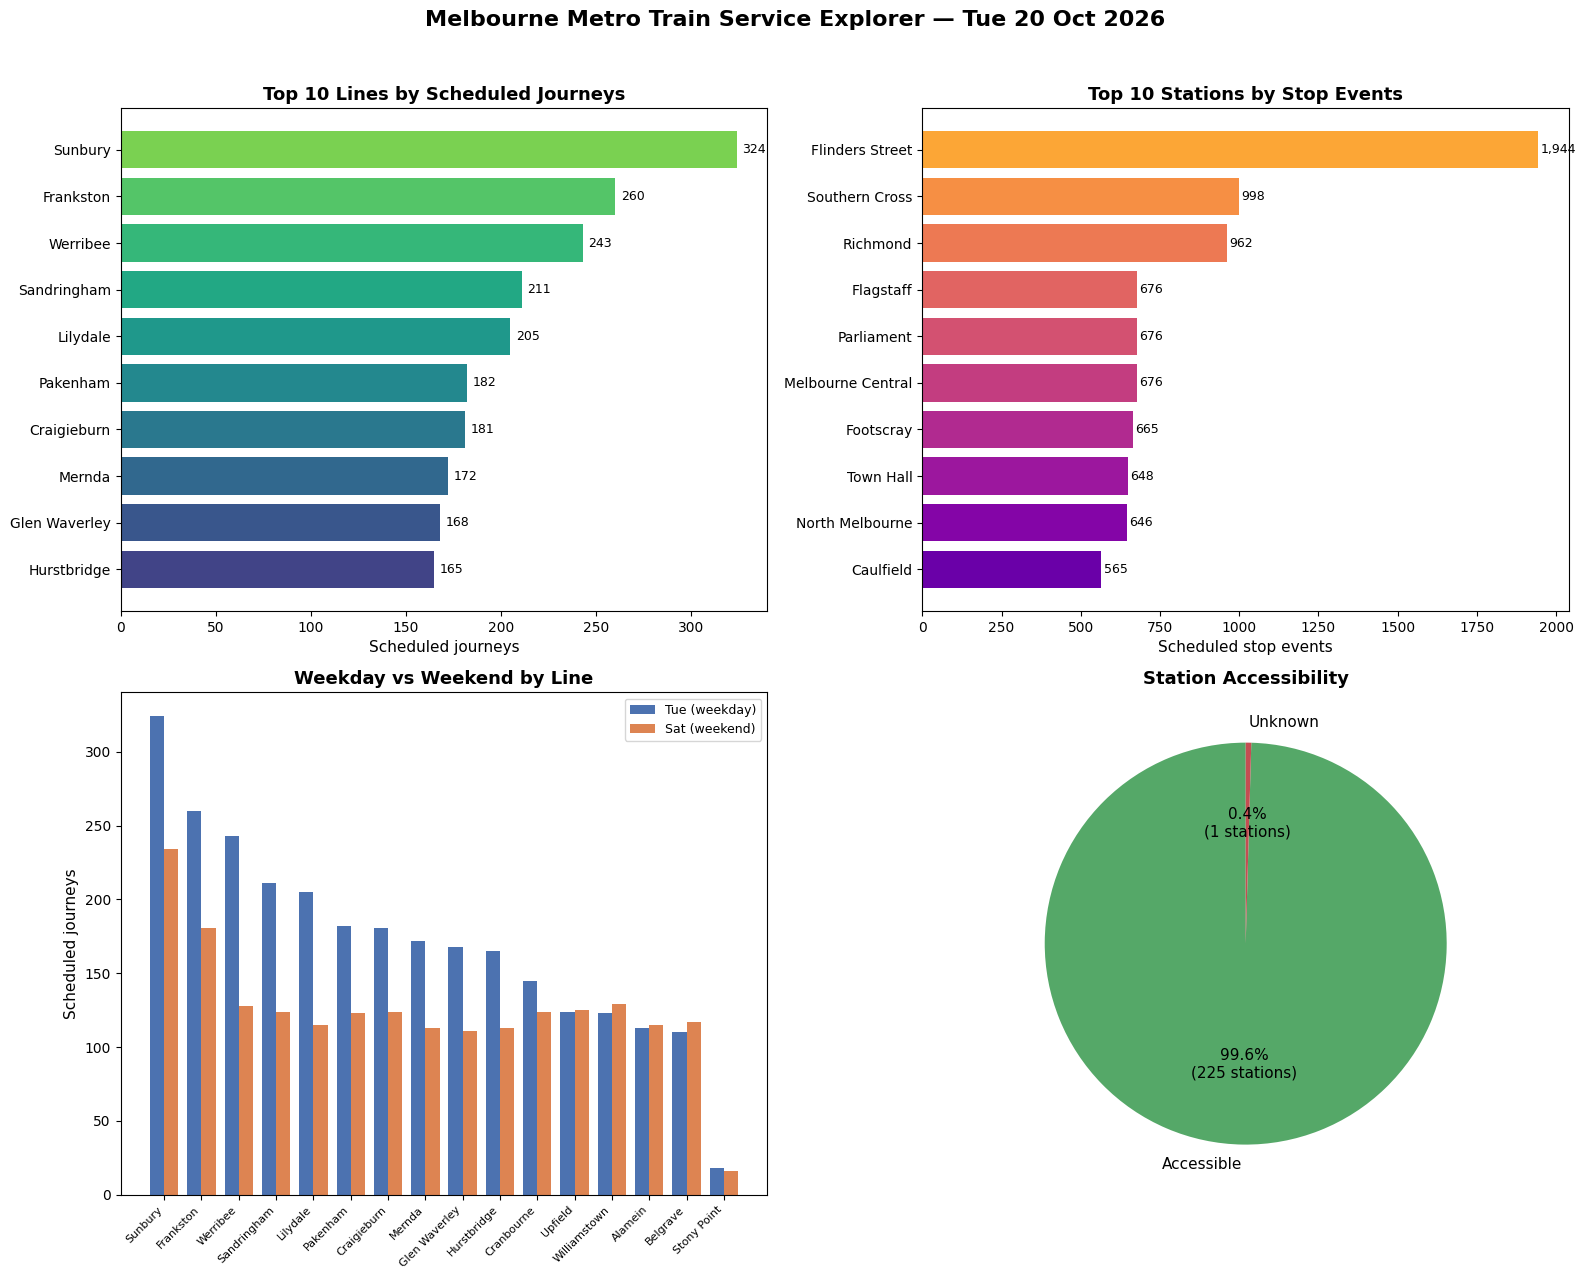

In [0]:
import matplotlib.pyplot as plt
import numpy as np

# ── Collect data for charts ───────────────────────────────────────────

# Q1a: Top 10 lines by weekday journeys
top_lines = (
    spark.table("workspace.default.pt_gold_daily_line_services")
    .orderBy(F.desc("scheduled_train_journeys"))
    .limit(10)
    .collect()
)
line_names = [r["line_name"] for r in top_lines]
line_journeys = [r["scheduled_train_journeys"] for r in top_lines]

# Q1b: Top 10 stations by stop events
top_stations = (
    spark.table("workspace.default.pt_gold_daily_station_activity")
    .orderBy(F.desc("scheduled_stop_events"))
    .limit(10)
    .collect()
)
station_names = [r["station_name"].replace(" Railway Station", "") for r in top_stations]
station_events = [r["scheduled_stop_events"] for r in top_stations]

# Q2: Weekday vs weekend comparison (all 16 lines, sorted by weekday)
comparison_rows = (
    spark.table("workspace.default.pt_gold_weekday_weekend_comparison")
    .orderBy(F.desc("weekday_journeys"))
    .collect()
)
comp_lines = [r["line_name"] for r in comparison_rows]
comp_weekday = [r["weekday_journeys"] for r in comparison_rows]
comp_weekend = [r["weekend_journeys"] for r in comparison_rows]

# Q3: Accessibility breakdown
accessibility_rows = (
    spark.table("workspace.default.pt_gold_station_accessibility")
    .orderBy(F.desc("station_count"))
    .collect()
)
acc_labels = [r["wheelchair_status"] for r in accessibility_rows]
acc_counts = [r["station_count"] for r in accessibility_rows]

# ── Build the 2×2 figure ──────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle("Melbourne Metro Train Service Explorer — Tue 20 Oct 2026",
             fontsize=16, fontweight="bold", y=0.98)

# Chart 1: Top 10 lines (horizontal bar)
ax1 = axes[0, 0]
colors1 = plt.cm.viridis(np.linspace(0.2, 0.8, len(line_names)))
bars1 = ax1.barh(line_names[::-1], line_journeys[::-1], color=colors1)
ax1.set_xlabel("Scheduled journeys", fontsize=11)
ax1.set_title("Top 10 Lines by Scheduled Journeys", fontsize=13, fontweight="bold")
for bar, val in zip(bars1, line_journeys[::-1]):
    ax1.text(val + 3, bar.get_y() + bar.get_height()/2, str(val),
            va="center", fontsize=9)

# Chart 2: Top 10 stations (horizontal bar)
ax2 = axes[0, 1]
colors2 = plt.cm.plasma(np.linspace(0.2, 0.8, len(station_names)))
bars2 = ax2.barh(station_names[::-1], station_events[::-1], color=colors2)
ax2.set_xlabel("Scheduled stop events", fontsize=11)
ax2.set_title("Top 10 Stations by Stop Events", fontsize=13, fontweight="bold")
for bar, val in zip(bars2, station_events[::-1]):
    ax2.text(val + 8, bar.get_y() + bar.get_height()/2, f"{val:,}",
            va="center", fontsize=9)

# Chart 3: Weekday vs weekend comparison (grouped bar)
ax3 = axes[1, 0]
x = np.arange(len(comp_lines))
width = 0.38
bars_wd = ax3.bar(x - width/2, comp_weekday, width, label="Tue (weekday)", color="#4C72B0")
bars_we = ax3.bar(x + width/2, comp_weekend, width, label="Sat (weekend)", color="#DD8452")
ax3.set_xticks(x)
ax3.set_xticklabels(comp_lines, rotation=45, ha="right", fontsize=8)
ax3.set_ylabel("Scheduled journeys", fontsize=11)
ax3.set_title("Weekday vs Weekend by Line", fontsize=13, fontweight="bold")
ax3.legend(fontsize=9)

# Chart 4: Accessibility (pie chart)
ax4 = axes[1, 1]
pie_colors = ["#55A868", "#C44E52"]
wedges, texts, autotexts = ax4.pie(
    acc_counts, labels=acc_labels, autopct=lambda p: f"{p:.1f}%\n({int(p*sum(acc_counts)/100)} stations)",
    colors=pie_colors, startangle=90, textprops={"fontsize": 11}
)
ax4.set_title("Station Accessibility", fontsize=13, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.96])
display(fig)
plt.close()